In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Cargar las 3 tablas
listings  = pd.read_csv("../datos/listings.csv.gz")
reviews   = pd.read_csv("../datos/reviews.csv.gz")
calendar  = pd.read_csv("../datos/calendar.csv.gz")

# Resumen de cada tabla
for nombre, df in [("listings", listings), ("reviews", reviews), ("calendar", calendar)]:
    print(f"\n{'='*50}")
    print(f"  {nombre.upper()}  →  {df.shape[0]:,} filas  ×  {df.shape[1]} columnas")
    print(f"{'='*50}")
    print(df.dtypes.to_string())
    print(f"\nMuestra:")
    display(df.head(3))


  LISTINGS  →  19,505 filas  ×  90 columnas
id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
name                                                str
description                                         str
neighborhood_overview                           float64
picture_url                                         str
host_id                                           int64
host_url                                            str
host_profile_id                                   int64
host_profile_url                                    str
host_name                                           str
host_since                                      float64
hosts_time_as_user_years                          int64
hosts_time_as_user_months                         int64
hos

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27841,https://www.airbnb.com/rooms/27841,20260914164224,2026-09-16,NaN,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,NaN,https://a0.muscache.com/pictures/38377482/1df3...,113734,...,4.81,4.93,4.81,112727.0,NaN,3,3,0,0,0.23
1,3043690,https://www.airbnb.com/rooms/3043690,20260914164224,2026-09-16,NaN,Room with a private,Located close to Parque Lourdes and within eas...,NaN,https://a0.muscache.com/pictures/46939629/35da...,15499337,...,4.63,4.63,4.50,NaN,NaN,2,0,2,0,0.05
2,3218908,https://www.airbnb.com/rooms/3218908,20260914164224,2026-09-16,NaN,"Nice vintage flat near to 93 park, well located","This flat is Inspired from the Vintage style, ...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,16300536,...,4.77,4.96,4.83,183725.0,NaN,1,1,0,0,1.09



  REVIEWS  →  568,675 filas  ×  6 columnas
listing_id       int64
id               int64
date               str
reviewer_id      int64
reviewer_name      str
comments           str

Muestra:


,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."



  CALENDAR  →  7,119,325 filas  ×  5 columnas
listing_id        int64
date                str
available           str
minimum_nights    int64
maximum_nights    int64

Muestra:


,listing_id,date,available,minimum_nights,maximum_nights
0,5546252,2026-09-16,t,30,1125
1,5546252,2026-09-17,t,30,1125
2,5546252,2026-09-18,t,30,1125


In [2]:
for nombre, df in [("listings", listings), ("reviews", reviews), ("calendar", calendar)]:
    print(f"{nombre}: {df.shape[0]:,} filas × {df.shape[1]} columnas")

listings: 19,505 filas × 90 columnas
reviews: 568,675 filas × 6 columnas
calendar: 7,119,325 filas × 5 columnas


In [3]:
print(listings.columns.tolist())

['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw', 'minimum_nig

*Veamos qué columnas elegir*


# Proyecto final: Airbnb Bogotá
## Pregunta 1: ¿cuánto se debería cobrar por noche según las características de la propiedad?

**Datos:** Inside Airbnb, Bogotá, septiembre 2026.
**Variable a predecir (y):** `price` (precio por noche en COP).
**Tipo de problema:** regresión, porque el precio es un número continuo.

In [4]:
import sys                    # sys da información del programa Python que se está ejecutando
print(sys.executable)         # imprime la ruta del Python que usa este notebook

c:\Users\123\AppData\Local\Programs\Python\Python312\python.exe


In [5]:
import warnings                                   # módulo para controlar los avisos (warnings) de Python
warnings.filterwarnings("ignore")                 # oculta los avisos para que el notebook se vea limpio

from pathlib import Path                          # Path sirve para manejar rutas de carpetas y archivos
import numpy as np                                # numpy: operaciones matemáticas y arreglos numéricos
import pandas as pd                               # pandas: manejo de tablas (DataFrames)
import matplotlib.pyplot as plt                   # matplotlib: para hacer gráficos
import seaborn as sns                             # seaborn: gráficos estadísticos más bonitos, se apoya en matplotlib

from sklearn.base import BaseEstimator, TransformerMixin   # clases base para crear mis propios transformadores
from sklearn.model_selection import train_test_split       # divide los datos en entrenamiento y prueba
from sklearn.model_selection import KFold                  # define cómo partir los datos para la validación cruzada
from sklearn.model_selection import cross_validate         # corre la validación cruzada y devuelve las métricas
from sklearn.compose import ColumnTransformer              # aplica un tratamiento distinto a cada grupo de columnas
from sklearn.compose import TransformedTargetRegressor     # entrena el modelo sobre un objetivo transformado (log) y devuelve la predicción en pesos
from sklearn.pipeline import Pipeline                      # encadena preparación de datos + modelo en un solo objeto
from sklearn.impute import SimpleImputer                   # rellena valores vacíos (nulos)
from sklearn.preprocessing import OneHotEncoder            # convierte categorías (texto) en columnas de 0 y 1
from sklearn.preprocessing import StandardScaler           # pone las variables numéricas en la misma escala
from sklearn.metrics import mean_absolute_error            # MAE: error promedio absoluto
from sklearn.metrics import mean_squared_error             # MSE: error cuadrático (de aquí sale el RMSE)
from sklearn.metrics import r2_score                       # R²: qué proporción de la variación explica el modelo

from sklearn.linear_model import LinearRegression, Ridge   # regresión lineal y su versión con penalización (Ridge)
from sklearn.neighbors import KNeighborsRegressor          # KNN: predice según los vecinos más parecidos
from sklearn.tree import DecisionTreeRegressor             # árbol de decisión
from sklearn.ensemble import RandomForestRegressor         # bosque aleatorio: muchos árboles que votan
from sklearn.ensemble import GradientBoostingRegressor     # boosting: árboles que corrigen los errores del anterior
from sklearn.svm import SVR                                # máquina de soporte vectorial para regresión
from sklearn.neural_network import MLPRegressor            # red neuronal sencilla (perceptrón multicapa)
from xgboost import XGBRegressor                           # XGBoost: boosting optimizado, muy usado en competencias

DATOS = Path("../datos")                          # ruta a la carpeta de datos (sube un nivel desde notebooks/ y entra a datos/)
pd.set_option("display.max_columns", 100)         # pandas mostrará hasta 100 columnas sin recortarlas con "..."
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")   # muestra los decimales con separador de miles y 2 decimales
sns.set_theme(style="whitegrid")                  # estilo de los gráficos: fondo claro con cuadrícula

print("Datos encontrados:", sorted(p.name for p in DATOS.glob("*.csv.gz")))   # lista los archivos .csv.gz de la carpeta datos, ordenados

Datos encontrados: ['calendar.csv.gz', 'listings.csv.gz', 'reviews.csv.gz']


## Paso 1: ¿Necesitamos ML?
Primero cargo la tabla `listings`, que tiene una fila por alojamiento publicado en Airbnb Bogotá, y miro qué trae.

In [6]:
listings = pd.read_csv(                          # lee el archivo CSV comprimido y lo guarda como tabla (DataFrame)
    DATOS / "listings.csv.gz",                   # ruta del archivo: la carpeta datos + el nombre del archivo
    dtype={"price": str},                        # fuerza la columna price a texto, porque viene como "$274,830.78" y hay que limpiarla después
    low_memory=False,                            # lee el archivo completo de una vez para que pandas no adivine mal los tipos de columna
)                                                # cierra la lectura

print("Filas y columnas:", listings.shape)       # muestra cuántas filas (alojamientos) y columnas (variables) tiene la tabla

Filas y columnas: (19505, 90)


In [7]:
print(listings["price"].head())                  # muestra los primeros 5 precios tal como vienen (texto con $ y comas)
print("Precios vacíos:", listings["price"].isna().sum())   # cuenta cuántos alojamientos no tienen precio (isna marca los vacíos y sum los cuenta)

0    $274,830.78
1     $71,692.74
2    $137,358.40
3    $173,779.33
4     $67,154.71
Name: price, dtype: str
Precios vacíos: 711


### Regla a mano (punto de partida)
Si no usara ML, un dueño podría mirar el precio típico (la mediana) de su barrio y cobrar eso. Calculo qué tan lejos queda esa regla del precio real. Si el modelo no la supera, no vale la pena usar ML.

In [8]:
def a_numero(serie):                                         # función que convierte el precio de texto a número
    sin_signo = serie.str.replace("$", "", regex=False)      # quita el signo $ del texto (regex=False para tratarlo como símbolo normal)
    sin_coma = sin_signo.str.replace(",", "", regex=False)   # quita las comas de los miles
    return sin_coma.astype(float)                            # convierte el texto limpio a número decimal

listings["price_num"] = a_numero(listings["price"])          # crea la columna price_num con el precio ya como número
datos = listings.dropna(subset=["price_num"]).copy()         # quita los 711 alojamientos sin precio (no sirven para aprender) y guarda una copia
print("Alojamientos con precio:", datos.shape[0])            # cuenta cuántas filas quedaron

Alojamientos con precio: 18794


In [9]:
train, test = train_test_split(                              # divide la tabla en dos partes: entrenamiento y prueba
    datos,                                                   # la tabla que vamos a dividir
    test_size=0.2,                                           # 20% de los datos se guarda para la prueba final
    random_state=42,                                         # semilla fija para que la división sea siempre la misma
)                                                            # cierra la división
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])   # muestra cuántas filas quedaron en cada parte

Entrenamiento: 15035 | Prueba: 3759


In [10]:
mediana_barrio = train.groupby("neighbourhood_cleansed")["price_num"].median()   # calcula el precio mediano de cada barrio, usando solo entrenamiento
mediana_global = train["price_num"].median()                 # mediana de toda la ciudad, por si en prueba aparece un barrio que no vimos
pred_regla = test["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)   # a cada alojamiento de prueba le asigna la mediana de su barrio (o la de la ciudad si no existe)

mae_regla = mean_absolute_error(test["price_num"], pred_regla)               # MAE: en promedio, cuántos pesos se equivoca la regla
rmse_regla = np.sqrt(mean_squared_error(test["price_num"], pred_regla))      # RMSE: error que castiga más los errores grandes
r2_regla = r2_score(test["price_num"], pred_regla)           # R²: qué proporción de la variación del precio explica la regla

print(f"MAE:  ${mae_regla:,.0f}")                            # imprime el MAE en pesos, sin decimales
print(f"RMSE: ${rmse_regla:,.0f}")                           # imprime el RMSE en pesos
print(f"R²:   {r2_regla:.3f}")                               # imprime el R² con 3 decimales

MAE:  $118,248
RMSE: $462,097
R²:   -0.009


### Conclusión: ¿necesitamos ML?
La regla de la mediana por barrio se equivoca en promedio $118.248 por noche (MAE), y su R² es casi 0 (-0.009), o sea que casi no explica el precio. Además el RMSE ($462.097) es mucho mayor que el MAE, así que seguramente hay precios extremos que estoy dejando pasar. Me queda claro que el barrio solo no basta: el precio también depende del tamaño y del tipo de alojamiento, entonces vale la pena probar modelos de ML que combinen varias variables. Este MAE de $118.248 es el número a superar.

## Paso 2: Datos

**De dónde salen:** Inside Airbnb, https://insideairbnb.com/get-the-data/ (sección "Bogotá, Distrito Capital, Colombia", compilado el 14 de septiembre de 2026).
**Licencia:** Creative Commons Attribution 4.0 (CC BY 4.0), se pueden usar citando la fuente.
**Cómo se descargan:** a mano desde esa página, son 3 archivos `.csv.gz` (los guardé en la carpeta `datos/`).

| Tabla | Qué es una fila |
|---|---|
| `listings` | un alojamiento publicado |
| `reviews` | un comentario que dejó un huésped |
| `calendar` | un alojamiento en un día futuro (si está disponible o no) |

**Etiqueta (lo que quiero predecir):** el precio por noche (`price`). Vale la pena porque un dueño nuevo no sabe cuánto cobrar, y si cobra de más no lo alquilan y si cobra de menos pierde plata.
**Complejidad:** son datos crudos y son 3 tablas. Tengo que armar yo una tabla principal con una fila por alojamiento.

In [11]:
calendar_cols = pd.read_csv(DATOS / "calendar.csv.gz", nrows=0).columns   # lee solo el encabezado (0 filas) para saber qué columnas tiene calendar sin cargarla toda
reviews_cols = pd.read_csv(DATOS / "reviews.csv.gz", nrows=0).columns     # lo mismo para reviews
print("calendar:", list(calendar_cols))              # imprime los nombres de las columnas de calendar
print("reviews:", list(reviews_cols))                # imprime los nombres de las columnas de reviews

calendar: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
reviews: ['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']


In [12]:
calendar = pd.read_csv(                              # carga la tabla calendar (7 millones de filas, por eso solo las columnas necesarias)
    DATOS / "calendar.csv.gz",                       # ruta del archivo
    usecols=["listing_id", "date", "available"],     # solo trae: id del alojamiento, fecha y si está disponible (así gasta menos memoria)
)                                                    # cierra la lectura
reviews = pd.read_csv(                               # carga la tabla reviews
    DATOS / "reviews.csv.gz",                        # ruta del archivo
    usecols=["listing_id", "date"],                  # solo trae: id del alojamiento y fecha del comentario (el texto lo usa la parte de sentimiento)
)                                                    # cierra la lectura

print(f"listings: {listings.shape[0]:,} filas x {listings.shape[1]} columnas")           # tamaño de listings
print(f"calendar: {len(calendar):,} filas x {len(calendar_cols)} columnas (en el archivo)")   # filas cargadas y columnas totales del archivo
print(f"reviews:  {len(reviews):,} filas x {len(reviews_cols)} columnas (en el archivo)")     # lo mismo para reviews

listings: 19,505 filas x 91 columnas
calendar: 7,119,325 filas x 5 columnas (en el archivo)
reviews:  568,675 filas x 6 columnas (en el archivo)


### Resumir calendar y reviews a una fila por alojamiento
Listings tiene una fila por alojamiento, pero calendar tiene una fila por alojamiento y por día, y reviews una por comentario. Para unirlas tengo que resumirlas:
- `pct_ocupado_90d`: de los próximos 90 días del calendario, qué proporción está no disponible (ocupado o bloqueado).
- `reviews_ult_12m`: cuántos comentarios recibió el alojamiento en el último año.

Todo se cuenta desde una **fecha de corte**, que es el "hoy" de los datos.

In [13]:
calendar["date"] = pd.to_datetime(calendar["date"])           # convierte la fecha de texto a fecha real, para poder comparar y restar
reviews["date"] = pd.to_datetime(reviews["date"])             # lo mismo para las fechas de los comentarios
fecha_corte = calendar["date"].min() - pd.Timedelta(days=1)   # el "hoy" de los datos: un día antes de que empiece el calendario

print("Fecha de corte:", fecha_corte.date())                  # muestra la fecha de corte
print("Calendar va de", calendar["date"].min().date(), "a", calendar["date"].max().date())   # primer y último día del calendario
print("Reviews van de", reviews["date"].min().date(), "a", reviews["date"].max().date())     # primer y último día con comentarios

Fecha de corte: 2026-09-15
Calendar va de 2026-09-16 a 2027-09-15
Reviews van de 2010-10-06 a 2026-09-16


In [14]:
primeros_90 = calendar[calendar["date"] <= fecha_corte + pd.Timedelta(days=90)]   # se queda solo con los primeros 90 días del calendario
esta_ocupado = primeros_90["available"] == "f"                # True si el día NO está disponible (en la tabla, "f" significa false)
pct_ocupado_90d = esta_ocupado.groupby(primeros_90["listing_id"]).mean()   # por alojamiento, el promedio de los True = proporción de días ocupados
pct_ocupado_90d.name = "pct_ocupado_90d"                      # le pone nombre a la columna resultante

en_ultimo_anio = (reviews["date"] > fecha_corte - pd.Timedelta(days=365)) & (reviews["date"] <= fecha_corte)   # True si el comentario cae en los 365 días antes del corte
reviews_ult_12m = reviews[en_ultimo_anio].groupby("listing_id").size()      # cuenta los comentarios del último año por alojamiento
reviews_ult_12m.name = "reviews_ult_12m"                      # le pone nombre a la columna resultante

print("Alojamientos con calendario:", len(pct_ocupado_90d))   # cuántos alojamientos aparecen en calendar
print("Alojamientos con comentarios en el último año:", len(reviews_ult_12m))   # cuántos recibieron al menos un comentario en el último año
print(pct_ocupado_90d.describe())                             # resumen estadístico del porcentaje ocupado (mínimo, promedio, máximo...)
print(reviews_ult_12m.describe())                             # resumen estadístico de los comentarios del último año

Alojamientos con calendario: 19505
Alojamientos con comentarios en el último año: 12674
count   19,505.00
mean         0.22
std          0.30
min          0.00
25%          0.02
50%          0.10
75%          0.29
max          1.00
Name: pct_ocupado_90d, dtype: float64
count   12,674.00
mean        15.17
std         23.09
min          1.00
25%          3.00
50%          8.00
75%         20.00
max        781.00
Name: reviews_ult_12m, dtype: float64


### Tabla principal (una fila por alojamiento)
Uno a `listings` las dos variables que resumí de calendar y reviews, usando el `id` del alojamiento. Los que no tuvieron comentarios en el último año quedan con 0. También creo `dias_desde_ultimo_review`: cuántos días pasaron entre el último comentario y la fecha de corte. Como cambió la tabla, repito la división entrenamiento/prueba con la misma semilla y compruebo que la regla a mano da lo mismo que antes.

In [15]:
datos = listings.merge(pct_ocupado_90d, left_on="id", right_index=True, how="left")      # pega el % ocupado a cada alojamiento, cruzando el id de listings con el listing_id de calendar
datos = datos.merge(reviews_ult_12m, left_on="id", right_index=True, how="left")         # pega los comentarios del último año, igual
datos["reviews_ult_12m"] = datos["reviews_ult_12m"].fillna(0)                            # los que no aparecen no tuvieron comentarios, así que valen 0
datos["dias_desde_ultimo_review"] = (fecha_corte - pd.to_datetime(datos["last_review"])).dt.days   # días entre el último comentario y la fecha de corte
datos["dias_desde_ultimo_review"] = datos["dias_desde_ultimo_review"].clip(lower=0)      # si salió negativo (comentario del día siguiente al corte) lo deja en 0
datos = datos.dropna(subset=["price_num"]).copy()                                        # quita los alojamientos sin precio, igual que en el Paso 1

print("Filas y columnas:", datos.shape)                                                  # tamaño de la tabla principal
print("¿Cada alojamiento aparece una sola vez?", datos["id"].is_unique)                  # comprueba que el cruce no duplicó filas
datos[["id", "neighbourhood_cleansed", "price_num", "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review"]].head()   # muestra las primeras 5 filas con las columnas nuevas

Filas y columnas: (18794, 94)
¿Cada alojamiento aparece una sola vez? True


,id,neighbourhood_cleansed,price_num,pct_ocupado_90d,reviews_ult_12m,dias_desde_ultimo_review
0,27841,Chapinero,"274,830.78",1.00,0.00,366.00
1,3043690,Chapinero,"71,692.74",0.00,0.00,"3,979.00"
2,3218908,Chapinero,"137,358.40",1.00,1.00,293.00
3,3247862,Chapinero,"173,779.33",1.00,0.00,"1,178.00"
4,3263631,Chapinero,"67,154.71",0.66,2.00,32.00


In [16]:
train, test = train_test_split(datos, test_size=0.2, random_state=42)       # repite la división 80/20 con la misma semilla de antes
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])        # muestra el tamaño de cada parte

mediana_barrio = train.groupby("neighbourhood_cleansed")["price_num"].median()   # vuelve a calcular la mediana de precio por barrio (solo entrenamiento)
mediana_global = train["price_num"].median()                                # mediana de toda la ciudad, por si aparece un barrio nuevo
pred_regla = test["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)   # asigna a cada alojamiento de prueba la mediana de su barrio
print(f"MAE de la regla a mano: ${mean_absolute_error(test['price_num'], pred_regla):,.0f}")   # tiene que dar lo mismo que en el Paso 1

Entrenamiento: 15035 | Prueba: 3759
MAE de la regla a mano: $118,248


## Paso 3: Limpieza
Reviso cuatro cosas: duplicados, formatos, faltantes y fugas. Empiezo por los duplicados y por los precios extremos, porque el RMSE era mucho más grande que el MAE y eso me hace sospechar que hay precios exagerados. Miro solo el conjunto de entrenamiento para no decidir nada con lo que debería ser la prueba final.

In [17]:
print("Filas completamente duplicadas:", datos.duplicated().sum())          # cuenta filas idénticas en todas las columnas
print("Ids repetidos:", datos["id"].duplicated().sum())                      # cuenta alojamientos que aparecen más de una vez
print()                                                                      # línea en blanco para separar
print(train["price_num"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99, 0.999]))   # resumen del precio con percentiles clave (1%, 5%, mediana, 95%, 99%, 99,9%)

Filas completamente duplicadas: 0
Ids repetidos: 0

count        15,035.00
mean        309,066.74
std       4,297,425.98
min          15,402.26
1%           34,389.75
5%           54,046.98
50%         160,993.92
95%         496,767.00
99%       1,275,922.67
99.9%     9,025,000.00
max     258,514,678.00
Name: price_num, dtype: float64


In [18]:
columnas_ver = ["price_num", "property_type", "room_type", "accommodates", "neighbourhood_cleansed"]   # columnas que quiero mirar de cada alojamiento
print("Los 10 más caros:")                                                   # título
display(train.nlargest(10, "price_num")[columnas_ver])                       # los 10 alojamientos con mayor precio
print("Los 5 más baratos:")                                                  # título
display(train.nsmallest(5, "price_num")[columnas_ver])                       # los 5 alojamientos con menor precio

Los 10 más caros:


,price_num,property_type,room_type,accommodates,neighbourhood_cleansed
4199,"258,514,678.00",Entire serviced apartment,Entire home/apt,2,Usaquen
18499,"232,260,501.00",Room in hotel,Private room,2,Teusaquillo
6696,"224,768,226.24",Private room in casa particular,Private room,1,Barrios Unidos
6577,"217,800,411.23",Private room in home,Private room,1,Barrios Unidos
1572,"160,000,000.00",Private room in home,Private room,2,Candelaria
3657,"150,025,000.00",Entire serviced apartment,Entire home/apt,3,Santa Fe
8203,"95,000,000.00",Entire rental unit,Entire home/apt,4,Teusaquillo
16361,"16,800,000.00",Entire rental unit,Entire home/apt,2,Chapinero
5493,"10,000,000.00",Private room in home,Private room,2,Puente Aranda
7357,"9,424,657.00",Entire rental unit,Entire home/apt,6,Fontibon


Los 5 más baratos:


,price_num,property_type,room_type,accommodates,neighbourhood_cleansed
1264,"15,402.26",Private room in condo,Private room,2,Bosa
1258,"15,896.45",Private room in home,Private room,2,Kennedy
2301,"18,794.63",Private room in home,Private room,4,Rafael Uribe Uribe
2078,"19,922.64",Private room in rental unit,Private room,1,Suba
4021,"20,025.18",Private room in casa particular,Private room,1,Teusaquillo


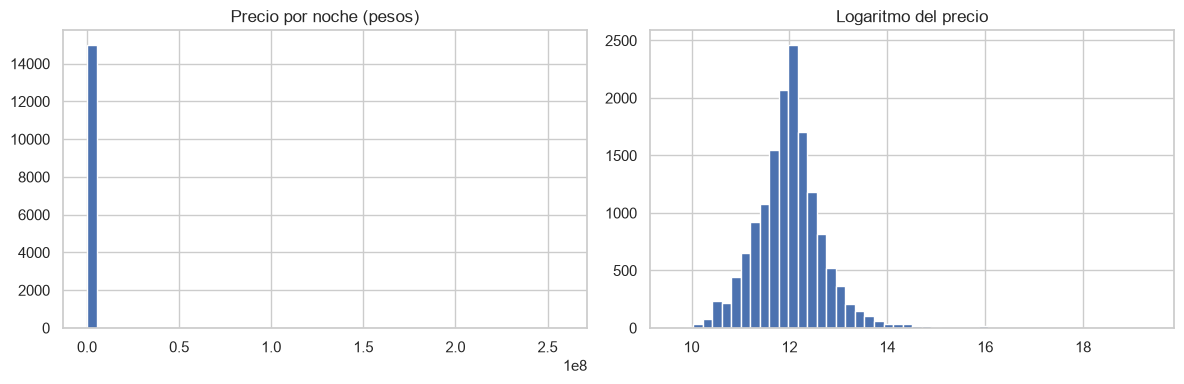

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))                              # crea una figura con dos gráficos lado a lado
ejes[0].hist(train["price_num"], bins=50)                                    # histograma del precio original, en 50 barras
ejes[0].set_title("Precio por noche (pesos)")                                # título del primer gráfico
ejes[1].hist(np.log1p(train["price_num"]), bins=50)                          # histograma del logaritmo del precio (log1p = log(1 + precio))
ejes[1].set_title("Logaritmo del precio")                                    # título del segundo gráfico
plt.tight_layout()                                                           # acomoda los gráficos para que no se pisen
plt.show()                                                                   # muestra la figura

### Decidir qué es un precio extremo
Hay precios imposibles, como $258 millones por noche para 2 personas, que son errores de digitación. Para no cortar a ojo uso la regla de Tukey sobre el logaritmo del precio: todo lo que pase de Q3 + 3 × IQR se considera extremo. Calculo el corte solo con entrenamiento y reviso qué queda justo arriba para confirmar que sí son errores.

In [20]:
log_precio = np.log1p(train["price_num"])                    # logaritmo del precio de entrenamiento, para medir los extremos en escala equilibrada
q1, q3 = log_precio.quantile([0.25, 0.75])                   # primer y tercer cuartil (el 25% y el 75% de los alojamientos quedan debajo)
iqr = q3 - q1                                                # rango intercuartílico: qué tan ancho es el 50% central
tope_log = q3 + 3 * iqr                                      # valla externa de Tukey: tercer cuartil más 3 veces el rango
tope_pesos = np.expm1(tope_log)                              # devuelve ese tope de logaritmo a pesos (expm1 deshace el log1p)
print(f"Tope de Tukey: ${tope_pesos:,.0f} por noche")        # imprime el tope en pesos

for t in sorted([2_000_000, 5_000_000, 10_000_000, tope_pesos]):   # prueba varios topes posibles, de menor a mayor
    n_train = (train["price_num"] > t).sum()                 # cuántos alojamientos de entrenamiento superan ese tope
    n_test = (test["price_num"] > t).sum()                   # cuántos de prueba lo superan (solo para saber el efecto, no para decidir)
    print(f"Más de ${t:>12,.0f}: entrenamiento {n_train:>4} | prueba {n_test:>4}")   # imprime el conteo alineado

Tope de Tukey: $2,083,053 por noche
Más de $   2,000,000: entrenamiento   72 | prueba   23
Más de $   2,083,053: entrenamiento   70 | prueba   23
Más de $   5,000,000: entrenamiento   28 | prueba    7
Más de $  10,000,000: entrenamiento    8 | prueba    1


In [21]:
columnas_ver = ["price_num", "property_type", "room_type", "accommodates", "neighbourhood_cleansed"]   # columnas que quiero mirar de cada alojamiento
arriba_del_tope = train[train["price_num"] > tope_pesos]     # alojamientos de entrenamiento que superan el tope de Tukey
print("Alojamientos sobre el tope:", len(arriba_del_tope))   # cuántos son
display(arriba_del_tope.sort_values("price_num")[columnas_ver].head(15))   # los 15 más baratos de esa zona: son los casos dudosos, justo arriba del corte

Alojamientos sobre el tope: 70


,price_num,property_type,room_type,accommodates,neighbourhood_cleansed
18769,"2,100,000.00",Entire rental unit,Entire home/apt,16,Santa Fe
19132,"2,120,000.00",Private room in bed and breakfast,Private room,16,Usaquen
16873,"2,223,223.00",Entire rental unit,Entire home/apt,16,Fontibon
8483,"2,267,460.00",Entire rental unit,Entire home/apt,2,Santa Fe
4970,"2,290,118.00",Entire serviced apartment,Entire home/apt,3,Chapinero
15809,"2,293,600.00",Entire home,Entire home/apt,16,Usaquen
15729,"2,313,516.50",Entire rental unit,Entire home/apt,16,Usaquen
19030,"2,350,000.00",Entire home,Entire home/apt,16,Usaquen
16661,"2,375,000.00",Entire rental unit,Entire home/apt,6,Usaquen
4888,"2,375,000.00",Entire serviced apartment,Entire home/apt,3,Chapinero


### Mejor criterio: precio por huésped
Con el corte de Tukey sobre el precio total me llevaba casas de 16 huéspedes a $2 millones, que parecen reales (son unos $130 mil por persona). Un precio total alto no es necesariamente un error: depende del tamaño. Entonces aplico la misma regla de Tukey pero sobre el **precio por huésped** (precio dividido entre `accommodates`), que sí compara alojamientos de tamaños distintos. El tope se calcula solo con entrenamiento y se aplica igual a entrenamiento y prueba, porque es una regla fija sobre errores de digitación en la etiqueta.

In [22]:
def por_huesped(df):                                                       # función que calcula el precio por huésped de una tabla
    return df["price_num"] / df["accommodates"].clip(lower=1)              # precio dividido entre huéspedes (mínimo 1 para no dividir por cero)

log_pp = np.log1p(por_huesped(train))                                      # logaritmo del precio por huésped en entrenamiento
q1, q3 = log_pp.quantile([0.25, 0.75])                                     # primer y tercer cuartil
iqr = q3 - q1                                                              # rango intercuartílico
tope_pp = np.expm1(q3 + 3 * iqr)                                           # tope de Tukey (Q3 + 3 × IQR) devuelto a pesos
print(f"Tope de Tukey por huésped: ${tope_pp:,.0f}")                       # imprime el tope

extremo_train = por_huesped(train) > tope_pp                               # marca los alojamientos de entrenamiento que superan el tope
extremo_test = por_huesped(test) > tope_pp                                 # marca los de prueba que lo superan
print("Extremos en entrenamiento:", extremo_train.sum(), "| en prueba:", extremo_test.sum())   # cuántos son en cada parte

salvados = arriba_del_tope[por_huesped(arriba_del_tope) <= tope_pp]        # los que Tukey sobre el total marcaba, pero esta regla deja
print("Casos que la regla anterior eliminaba y esta conserva:", len(salvados))   # cuántos son
display(train[extremo_train].assign(por_huesped=por_huesped(train[extremo_train]))   # tabla de los extremos, con el precio por huésped agregado
        .sort_values("por_huesped")[columnas_ver + ["por_huesped"]].head(15))        # ordenada de menor a mayor, solo los 15 primeros: los casos dudosos

Tope de Tukey por huésped: $665,251
Extremos en entrenamiento: 71 | en prueba: 23
Casos que la regla anterior eliminaba y esta conserva: 25


,price_num,property_type,room_type,accommodates,neighbourhood_cleansed,por_huesped
14624,"1,443,979.00",Entire loft,Entire home/apt,2,Chapinero,"721,989.50"
6459,"1,500,000.00",Private room in guesthouse,Private room,2,Engativa,"750,000.00"
1717,"763,262.13",Private room in rental unit,Private room,1,Suba,"763,262.13"
4970,"2,290,118.00",Entire serviced apartment,Entire home/apt,3,Chapinero,"763,372.67"
16346,"3,840,000.00",Entire rental unit,Entire home/apt,5,Teusaquillo,"768,000.00"
148,"786,501.49",Private room in home,Private room,1,Teusaquillo,"786,501.49"
8541,"1,580,000.00",Entire rental unit,Entire home/apt,2,Chapinero,"790,000.00"
4888,"2,375,000.00",Entire serviced apartment,Entire home/apt,3,Chapinero,"791,666.67"
8240,"2,375,000.00",Entire rental unit,Entire home/apt,3,Chapinero,"791,666.67"
18926,"1,599,000.00",Entire rental unit,Entire home/apt,2,Teusaquillo,"799,500.00"


### Aplicar el corte
Quito los alojamientos con precio por huésped mayor a $665.251 (el tope de Tukey). Son 71 de entrenamiento y 23 de prueba, cerca del 0,5 %, y los saco de los dos grupos porque son errores en la etiqueta y no tiene sentido medir al modelo contra precios imposibles. Después recalculo la regla a mano para comparar antes y después. Más adelante compruebo con los modelos que quitarlos mejora el error.

In [ ]:
def regla_a_mano(entreno, prueba):                                         # función: predice con la mediana de precio del barrio
    mediana_barrio = entreno.groupby("neighbourhood_cleansed")["price_num"].median()   # mediana de precio por barrio, calculada solo con entrenamiento
    mediana_global = entreno["price_num"].median()                         # mediana de toda la ciudad, por si aparece un barrio nuevo
    return prueba["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)   # le asigna a cada alojamiento de prueba la mediana de su barrio

def metricas(y_real, y_pred):                                              # función: calcula las 4 métricas del proyecto
    return {                                                               # devuelve un diccionario con las métricas
        "MAE": mean_absolute_error(y_real, y_pred),                        # error promedio en pesos
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),               # error que castiga más los fallos grandes
        "R2": r2_score(y_real, y_pred),                                    # proporción de la variación que se explica
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_real), np.log1p(y_pred))),   # error en escala logarítmica (error relativo)
    }                                                                      # cierra el diccionario

antes = metricas(test["price_num"], regla_a_mano(train, test))             # métricas de la regla a mano ANTES de limpiar

train = train[por_huesped(train) <= tope_pp].copy()                        # se queda en entrenamiento solo con los que NO superan el tope
test = test[por_huesped(test) <= tope_pp].copy()                           # lo mismo en prueba
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])        # tamaños después de limpiar

despues = metricas(test["price_num"], regla_a_mano(train, test))           # métricas de la regla a mano DESPUÉS de limpiar
tabla = pd.DataFrame({"Antes de limpiar": antes, "Después de limpiar": despues})   # junta ambos resultados en una tabla

Entrenamiento: 14964 | Prueba: 3736


,Antes de limpiar,Después de limpiar
MAE,"118,247.909","92,943.425"
RMSE,"462,096.509","202,498.887"
R2,-0.009,0.005
RMSLE,0.663,0.621


In [24]:
display(tabla.map(lambda x: f"{x:,.3f}"))     # muestra la tabla de antes y después; map aplica a cada número un formato con miles y 3 decimales

,Antes de limpiar,Después de limpiar
MAE,"118,247.909","92,943.425"
RMSE,"462,096.509","202,498.887"
R2,-0.009,0.005
RMSLE,0.663,0.621


### Conclusión: precios extremos
Quité 71 alojamientos de entrenamiento y 23 de prueba (cerca del 0,5 %) cuyo precio por huésped pasaba de $665.251, el tope de Tukey. Con el precio total me llevaba casas reales de 16 huéspedes, y con el precio por huésped no. Después de limpiar, la regla a mano mejoró: el MAE bajó de $118.248 a $92.943, el RMSE de $462.097 a $202.499 y el RMSLE de 0,663 a 0,621. El R² sigue casi en cero (0,005), o sea que el barrio solo no explica el precio. Desde ahora, la regla a mano con MAE $92.943 es el número a superar.

### Faltantes
Reviso cuáles de las columnas candidatas tienen datos vacíos y cuántos. Para cada una con faltantes voy a comparar el error de varias formas de rellenarlos, como hizo el profesor con la edad en Titanic, en lugar de escoger la media sin justificar.

In [25]:
columnas_candidatas = [                                                    # lista de las columnas que pensamos usar para predecir
    "property_type", "room_type", "neighbourhood_cleansed",                # tipo de propiedad, tipo de habitación y barrio
    "latitude", "longitude",                                               # ubicación exacta
    "accommodates", "bedrooms", "beds", "bathrooms", "bathrooms_text",     # capacidad, habitaciones, camas y baños
    "amenities", "minimum_nights", "host_listings_count", "host_is_superhost",   # comodidades, noches mínimas, cuántos alojamientos tiene el dueño, superhost
    "review_scores_rating", "availability_90",                             # calificación y disponibilidad a 90 días
    "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",      # las tres variables que armamos desde calendar y reviews
]                                                                          # cierra la lista

presentes = [c for c in columnas_candidatas if c in train.columns]         # las candidatas que sí existen en la tabla
ausentes = [c for c in columnas_candidatas if c not in train.columns]      # las que no existen (por si algún nombre está distinto)
print("No existen en la tabla:", ausentes)                                 # muestra las que faltan, debería salir vacío

resumen = pd.DataFrame({                                                   # arma una tabla resumen
    "tipo": train[presentes].dtypes.astype(str),                           # tipo de dato de cada columna
    "faltantes": train[presentes].isna().sum(),                            # cuántos valores vacíos tiene cada una
    "porcentaje": (train[presentes].isna().mean() * 100).round(1),         # el mismo dato en porcentaje
}).sort_values("faltantes", ascending=False)                               # ordena de la que más faltantes tiene a la que menos
display(resumen)                                                           # muestra la tabla

No existen en la tabla: []


,tipo,faltantes,porcentaje
bathrooms,float64,14964,100.00
review_scores_rating,float64,3010,20.10
dias_desde_ultimo_review,float64,3010,20.10
beds,float64,167,1.10
bathrooms_text,str,25,0.20
minimum_nights,float64,6,0.00
bedrooms,float64,3,0.00
neighbourhood_cleansed,str,0,0.00
room_type,str,0,0.00
property_type,str,0,0.00


### Cómo rellenar los faltantes
Para no escoger la media sin justificar, comparo cuatro formas de rellenar: la media, la mediana global, la mediana por grupo y una regresión (bosque aleatorio). Tomo los valores que sí conozco, escondo el 20 %, los adivino con cada método y mido el error (MAE). Gana el de menor error. Lo hago en `beds`, `bedrooms` y `review_scores_rating`. Las otras (`minimum_nights`, 6 faltantes) son tan pocas que uso la mediana.

In [26]:
def comparar_imputacion(columna, grupo):                                   # función: compara 4 formas de rellenar una columna; grupo es la columna para la mediana por grupo
    conocidos = train[train[columna].notna()].copy()                       # se queda solo con las filas donde el valor sí existe
    X = pd.concat([                                                        # arma las variables con las que la regresión intentará adivinar
        conocidos[["accommodates", "latitude", "longitude"]],              # capacidad y ubicación
        pd.get_dummies(conocidos["room_type"]).astype(float),              # tipo de habitación convertido en columnas de 0 y 1
    ], axis=1)                                                             # las une lado a lado
    y = conocidos[columna]                                                 # el valor real que queremos adivinar
    X_fit, X_ev, y_fit, y_ev = train_test_split(X, y, test_size=0.2, random_state=42)   # esconde 20% (evaluación) y deja 80% (para aprender)

    err_media = mean_absolute_error(y_ev, np.full(len(y_ev), y_fit.mean()))            # método 1: adivinar siempre la media
    err_mediana = mean_absolute_error(y_ev, np.full(len(y_ev), y_fit.median()))        # método 2: adivinar siempre la mediana
    med_grupo = y_fit.groupby(conocidos.loc[y_fit.index, grupo]).median()              # método 3: mediana de cada grupo (calculada con el 80%)
    pred_grupo = conocidos.loc[y_ev.index, grupo].map(med_grupo).fillna(y_fit.median())   # a cada fila escondida le asigna la mediana de su grupo
    err_grupo = mean_absolute_error(y_ev, pred_grupo)                      # error del método 3
    bosque = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)       # método 4: un bosque aleatorio (100 árboles, semilla fija)
    bosque.fit(X_fit, y_fit)                                               # el bosque aprende con el 80%
    err_reg = mean_absolute_error(y_ev, bosque.predict(X_ev))              # error del método 4 sobre el 20% escondido

    return {                                                               # devuelve los 4 errores en un diccionario
        "Media": err_media, "Mediana global": err_mediana,                 # errores de los métodos 1 y 2
        "Mediana por grupo": err_grupo, "Regresión (bosque)": err_reg,     # errores de los métodos 3 y 4
    }                                                                      # cierra el diccionario

resultados = pd.DataFrame({                                                # tabla con una fila por columna a rellenar
    "beds (grupo: accommodates)": comparar_imputacion("beds", "accommodates"),             # camas, agrupando por capacidad
    "bedrooms (grupo: accommodates)": comparar_imputacion("bedrooms", "accommodates"),     # habitaciones, agrupando por capacidad
    "review_scores_rating (grupo: room_type)": comparar_imputacion("review_scores_rating", "room_type"),   # calificación, agrupando por tipo de habitación
}).T                                                                       # .T gira la tabla: columnas pasan a ser filas
display(resultados.map(lambda x: f"{x:,.3f}"))                             # muestra los errores con 3 decimales

,Media,Mediana global,Mediana por grupo,Regresión (bosque)
beds (grupo: accommodates),0.999,0.972,0.411,0.530
bedrooms (grupo: accommodates),0.694,0.469,0.320,0.371
review_scores_rating (grupo: room_type),0.274,0.239,0.239,0.285


### Conclusión: faltantes
- `bathrooms` está vacía al 100 %: la descarto y saco los baños de `bathrooms_text`.
- `beds` y `bedrooms`: relleno con la mediana según `accommodates`. Probé media, mediana global, mediana por grupo y bosque aleatorio, y la mediana por grupo tuvo el menor error (MAE 0,411 en camas y 0,320 en habitaciones, contra 0,999 y 0,694 de la media). La regresión fue peor y más complicada.
- `review_scores_rating`: mediana global (MAE 0,239, empata con la mediana por tipo de habitación y es más simple).
- `dias_desde_ultimo_review` y `review_scores_rating` faltan en los mismos 3.010 alojamientos (20,1 %), los que nunca recibieron un comentario. Ahí el dato no existe, así que además de rellenar con la mediana creo una columna `sin_reviews` que marca esos casos.
- `minimum_nights` (6 faltantes): mediana.
Todo esto lo pongo dentro del Pipeline para que se aprenda solo con entrenamiento.

### Fugas
Una fuga es una columna que solo se conoce después de poner el precio, o que se calcula con el precio. Reviso que ninguna de mis columnas candidatas lo sea. La columna `estimated_revenue_l365d` (ingreso estimado del año) la dejo afuera: debería ser precio × noches ocupadas, o sea que ya trae el precio adentro. Lo compruebo.

In [27]:
con_ocupacion = train[train["estimated_occupancy_l365d"] > 0]              # se queda con los alojamientos que tienen al menos una noche ocupada estimada
ratio = con_ocupacion["estimated_revenue_l365d"] / con_ocupacion["estimated_occupancy_l365d"]   # ingreso dividido entre noches ocupadas: si es precio × noches, esto debe dar el precio
coincide = np.isclose(ratio, con_ocupacion["price_num"], rtol=0.01)        # True si ese cociente es igual al precio publicado (con 1% de tolerancia)
print(f"El ingreso estimado / noches ocupadas coincide con el precio en el {coincide.mean() * 100:.1f}% de los casos")   # imprime qué porcentaje coincide

El ingreso estimado / noches ocupadas coincide con el precio en el 100.0% de los casos


In [28]:
numericas = [                                                              # variables numéricas candidatas para revisar
    "accommodates", "bedrooms", "beds", "latitude", "longitude",           # capacidad y ubicación
    "minimum_nights", "host_listings_count", "review_scores_rating",       # noches mínimas, alojamientos del dueño y calificación
    "availability_90", "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",   # actividad
    "estimated_revenue_l365d",                                             # la columna que sospecho que es fuga, para comparar
]                                                                          # cierra la lista
corr = train[numericas].corrwith(np.log1p(train["price_num"]), method="spearman")   # correlación de rangos (Spearman) de cada columna con el logaritmo del precio
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)         # ordena de la correlación más fuerte a la más débil (sin importar el signo)
display(corr.to_frame("correlación con log(precio)").map(lambda x: f"{x:,.3f}"))   # muestra la tabla con 3 decimales

,correlación con log(precio)
accommodates,0.509
beds,0.374
bedrooms,0.344
longitude,0.326
estimated_revenue_l365d,0.268
host_listings_count,0.215
minimum_nights,-0.203
latitude,0.134
reviews_ult_12m,0.129
pct_ocupado_90d,0.098


### Conclusión: fugas
`estimated_revenue_l365d` es una fuga: comprobé que el ingreso dividido entre las noches ocupadas da exactamente el precio en el 100 % de los casos, o sea que se calcula con el precio. La dejo afuera. Aunque su correlación con el precio es de solo 0,268, no se puede usar porque ya contiene lo que quiero predecir. Las demás columnas candidatas no pasan de una correlación de 0,51 (la más alta es `accommodates`), así que no veo fugas en ellas. Las variables de actividad (calificación, disponibilidad, % ocupado y comentarios) no son fuga, pero un dueño nuevo no las tiene, así que más adelante comparo los modelos con y sin ellas.

## Paso 4: Columnas
Decido qué columnas entran al modelo, cuáles creo y cuáles descarto. Antes reviso cómo vienen las que no puedo usar tal cual: `bathrooms_text` (texto con el número de baños), `amenities` (lista de comodidades en texto), `property_type` (muchas categorías) y `host_is_superhost` (texto "t" o "f").

In [29]:
print(train["bathrooms_text"].value_counts(dropna=False).head(15))         # los 15 textos de baños más frecuentes (dropna=False cuenta también los vacíos)
print()                                                                    # línea en blanco para separar
print("Ejemplo de amenities:", train["amenities"].iloc[0][:300])           # los primeros 300 caracteres de la lista de comodidades del primer alojamiento
print()                                                                    # línea en blanco
print("Tipos de propiedad distintos:", train["property_type"].nunique())   # cuántas categorías distintas hay de tipo de propiedad
print(train["property_type"].value_counts().head(10))                      # las 10 categorías más frecuentes
print()                                                                    # línea en blanco
print(train["host_is_superhost"].value_counts(dropna=False))               # cuántos superhost "t", "f" y vacíos hay

bathrooms_text
1 bath              7809
1 private bath      1973
2 baths             1874
1.5 baths            895
1 shared bath        857
2.5 baths            359
3 baths              259
2 shared baths       152
1.5 shared baths      98
3.5 baths             90
4 baths               67
0 shared baths        67
3 shared baths        46
0 baths               42
5 baths               30
Name: count, dtype: int64

Ejemplo de amenities: ["Shampoo", "Coffee maker", "Hair dryer", "Iron", "Room-darkening shades", "Clothing storage", "Wifi", "Body soap", "TV", "Breakfast", "Pets allowed", "Hangers", "Building staff", "Fire extinguisher", "Safe", "Air conditioning", "Heating", "Free parking on premises", "Elevator", "Dedicated workspace

Tipos de propiedad distintos: 65
property_type
Entire rental unit             8203
Private room in rental unit    1129
Private room in home           1057
Entire loft                     899
Entire serviced apartment       828
Room in hotel                   

In [30]:
con_texto = train["bathrooms_text"].dropna()                               # textos de baños, sin los vacíos
sin_numero = con_texto[~con_texto.str.contains(r"\d")]                     # se queda con los textos que NO tienen ningún dígito (el símbolo ~ significa "no")
print("Textos de baños sin número:", sin_numero.value_counts().to_dict())  # muestra cuáles son y cuántas veces aparece cada uno

frecuencia = train["property_type"].value_counts() / len(train) * 100      # porcentaje de alojamientos de cada tipo de propiedad
print("Tipos de propiedad con menos del 1% de los datos:", (frecuencia < 1).sum(), "de", len(frecuencia))   # cuántas categorías son raras
print("Esos tipos raros suman:", round(frecuencia[frecuencia < 1].sum(), 1), "% de los datos")              # qué porcentaje de los datos representan todos juntos

print("Valores de host_is_superhost:", train["host_is_superhost"].unique())   # valores distintos de la columna superhost (incluye vacío si lo hay)

Textos de baños sin número: {'Shared half-bath': 29, 'Half-bath': 23, 'Private half-bath': 17, 'No bathroom': 1}
Tipos de propiedad con menos del 1% de los datos: 55 de 65
Esos tipos raros suman: 6.6 % de los datos
Valores de host_is_superhost: <StringArray>
['f', 't']
Length: 2, dtype: str


### Crear las columnas nuevas
Hago una clase propia, `CrearColumnas`, para que estas transformaciones queden dentro del Pipeline. Crea:
- `n_banos`: número de baños sacado de `bathrooms_text` (los "medio baño" valen 0,5 y "No bathroom" vale 0).
- `bano_compartido`: 1 si el baño es compartido. Un baño compartido seguramente baja el precio.
- `n_amenities`: cuántas comodidades tiene el alojamiento (cuento los elementos de la lista).
- `es_superhost`: la columna de texto "t"/"f" pasada a 1/0.
- `sin_reviews`: 1 si el alojamiento nunca recibió un comentario (le falta la calificación).

In [31]:
import json                                                                # json sirve para leer la lista de comodidades que viene como texto

def contar_amenities(texto):                                               # función: cuenta cuántas comodidades hay en el texto
    try:                                                                   # intenta leer el texto como lista
        return len(json.loads(texto))                                      # convierte el texto en lista y cuenta sus elementos
    except (TypeError, ValueError):                                        # si el texto está vacío o dañado
        return np.nan                                                      # devuelve vacío (se rellena después)

class CrearColumnas(BaseEstimator, TransformerMixin):                      # clase propia: sigue las reglas de sklearn para poder ir dentro del Pipeline
    def fit(self, X, y=None):                                              # fit: aquí no hay nada que aprender
        return self                                                        # devuelve el mismo objeto, como exige sklearn

    def transform(self, X):                                                # transform: aplica los cambios a la tabla
        X = X.copy()                                                       # trabaja sobre una copia para no modificar la tabla original
        texto = X["bathrooms_text"].str.lower()                            # pasa el texto de baños a minúsculas para compararlo fácil
        numero = texto.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)    # extrae el primer número del texto (con decimales, como 1.5)
        numero = numero.mask(texto.str.contains("half", na=False) & numero.isna(), 0.5)   # si dice "half" y no tiene número, vale 0,5
        numero = numero.mask(texto.str.contains("no bathroom", na=False), 0.0)            # si dice "no bathroom", vale 0
        X["n_banos"] = numero                                              # guarda el número de baños como columna nueva
        X["bano_compartido"] = texto.str.contains("shared", na=False).astype(int)         # 1 si el texto dice "shared", 0 si no
        X["n_amenities"] = X["amenities"].apply(contar_amenities)          # cuenta las comodidades de cada alojamiento
        X["es_superhost"] = (X["host_is_superhost"] == "t").astype(int)    # 1 si es superhost ("t"), 0 si no
        X["sin_reviews"] = X["review_scores_rating"].isna().astype(int)    # 1 si nunca tuvo comentarios (no tiene calificación)
        return X                                                           # devuelve la tabla con las columnas nuevas

In [32]:
con_nuevas = CrearColumnas().fit_transform(train)                          # aplica la clase a entrenamiento (fit_transform = fit y luego transform)
nuevas = ["bathrooms_text", "n_banos", "bano_compartido", "n_amenities",   # columnas que quiero revisar: la original y la creada, lado a lado
          "host_is_superhost", "es_superhost", "review_scores_rating", "sin_reviews"]
display(con_nuevas[nuevas].head(8))                                        # muestra las primeras 8 filas
print("Faltantes en n_banos:", con_nuevas["n_banos"].isna().sum())         # cuántos baños quedaron vacíos
print(con_nuevas["n_banos"].value_counts().sort_index().head(12))          # cuántos alojamientos hay por cada cantidad de baños

,bathrooms_text,n_banos,bano_compartido,n_amenities,host_is_superhost,es_superhost,review_scores_rating,sin_reviews
3845,1 private bath,1.00,0,27,f,0,5.00,0
12649,1.5 baths,1.50,0,22,f,0,NaN,1
13094,1 bath,1.00,0,25,t,1,4.82,0
7578,1 bath,1.00,0,34,t,1,4.84,0
14810,1 private bath,1.00,0,27,t,1,NaN,1
17665,1 bath,1.00,0,24,f,0,4.81,0
5936,1 bath,1.00,0,25,t,1,4.75,0
4905,1 bath,1.00,0,33,f,0,4.00,0


Faltantes en n_banos: 25
n_banos
0.00      110
0.50       69
1.00    10639
1.50      993
2.00     2026
2.50      382
3.00      305
3.50       95
4.00       95
4.50       31
5.00       48
5.50        5
Name: count, dtype: int64


In [33]:
print("Alojamientos con baño compartido:", con_nuevas["bano_compartido"].sum())   # cuántos tienen baño compartido (suma de los 1)
print()                                                                    # línea en blanco para separar
print("Precio mediano según baño compartido (0 = privado, 1 = compartido):")   # título
print(con_nuevas.groupby("bano_compartido")["price_num"].median())         # precio mediano de cada grupo
print()                                                                    # línea en blanco para separar
nuevas_cols = ["n_banos", "bano_compartido", "n_amenities", "es_superhost", "sin_reviews"]   # las 5 columnas que creamos
corr_nuevas = con_nuevas[nuevas_cols].corrwith(np.log1p(con_nuevas["price_num"]), method="spearman")   # correlación de cada una con el logaritmo del precio
print("Correlación de las columnas nuevas con log(precio):")              # título
print(corr_nuevas.round(3))                                                # imprime las correlaciones con 3 decimales

Alojamientos con baño compartido: 1371

Precio mediano según baño compartido (0 = privado, 1 = compartido):
bano_compartido
0   167,998.00
1    70,000.00
Name: price_num, dtype: float64

Correlación de las columnas nuevas con log(precio):
n_banos            0.32
bano_compartido   -0.34
n_amenities        0.33
es_superhost       0.13
sin_reviews       -0.12
dtype: float64


### Rellenar faltantes por grupo
Hago una segunda clase propia, `RellenarPorGrupo`, que aplica lo que salió de comparar errores: rellenar `beds` y `bedrooms` con la mediana según `accommodates`. Le sumo `n_banos` (25 faltantes) porque también depende de cuánta gente cabe. La clase aprende las medianas solo con entrenamiento en `fit`, y las usa en `transform`, para no mezclar datos de prueba.

In [34]:
class RellenarPorGrupo(BaseEstimator, TransformerMixin):                   # clase propia que rellena vacíos con la mediana de cada grupo
    def __init__(self, columnas, grupo):                                   # al crearla se le dice qué columnas rellenar y por cuál agrupar
        self.columnas = columnas                                           # guarda la lista de columnas a rellenar
        self.grupo = grupo                                                 # guarda la columna que define los grupos

    def fit(self, X, y=None):                                              # fit: aprende las medianas (solo con los datos que reciba)
        self.medianas_ = {c: X.groupby(self.grupo)[c].median() for c in self.columnas}   # mediana de cada columna por grupo (el guion bajo final indica "aprendido")
        self.globales_ = {c: X[c].median() for c in self.columnas}         # mediana general de cada columna, por si aparece un grupo nuevo
        return self                                                        # devuelve el mismo objeto, como exige sklearn

    def transform(self, X):                                                # transform: rellena los vacíos usando lo aprendido
        X = X.copy()                                                       # trabaja sobre una copia
        for c in self.columnas:                                            # recorre cada columna a rellenar
            por_grupo = X[self.grupo].map(self.medianas_[c])               # a cada fila le asigna la mediana de su grupo
            X[c] = X[c].fillna(por_grupo).fillna(self.globales_[c])        # rellena con la del grupo y, si no hay, con la general
        return X                                                           # devuelve la tabla rellenada

In [35]:
cols_relleno = ["beds", "bedrooms", "n_banos"]                             # las tres columnas que rellena la clase
relleno = RellenarPorGrupo(cols_relleno, "accommodates")                   # crea la clase: rellena esas columnas según la capacidad
rellenado = relleno.fit_transform(con_nuevas)                              # aprende las medianas y rellena en un solo paso
print("Faltantes ANTES:")                                                  # título
print(con_nuevas[cols_relleno].isna().sum())                               # vacíos que había
print("Faltantes DESPUÉS:")                                                # título
print(rellenado[cols_relleno].isna().sum())                                # vacíos que quedaron (deben ser 0)

Faltantes ANTES:
beds        167
bedrooms      3
n_banos      25
dtype: int64
Faltantes DESPUÉS:
beds        0
bedrooms    0
n_banos     0
dtype: int64


### Preprocesamiento completo
Junto todo en un solo objeto para meterlo al Pipeline de cada modelo. Primero `CrearColumnas`, luego `RellenarPorGrupo`, y al final un `ColumnTransformer`: a las numéricas les rellena lo que quede con la mediana (calificación, días desde el último comentario, noches mínimas) y las escala; a las categóricas las pasa a 0/1 y agrupa en "otros" las que pesan menos del 1 %. Hago una función con un interruptor para armarlo **sin** o **con** las variables de actividad (calificación, disponibilidad, % ocupado, comentarios), porque un dueño nuevo no las tiene.

In [36]:
CATEGORICAS = ["property_type", "room_type", "neighbourhood_cleansed"]    # columnas de texto que se convierten en 0/1
NUM_BASE = [                                                               # numéricas que cualquier dueño conoce desde el día uno
    "latitude", "longitude", "accommodates", "bedrooms", "beds",           # ubicación, capacidad, habitaciones y camas
    "n_banos", "bano_compartido", "n_amenities",                           # baños, baño compartido y número de comodidades (las creamos nosotros)
    "minimum_nights", "host_listings_count", "es_superhost",               # noches mínimas, alojamientos del dueño y superhost
]                                                                          # cierra la lista
NUM_ACTIVIDAD = [                                                          # numéricas de actividad: solo existen si el alojamiento ya operó
    "review_scores_rating", "availability_90", "pct_ocupado_90d",          # calificación, disponibilidad a 90 días y % ocupado
    "reviews_ult_12m", "dias_desde_ultimo_review", "sin_reviews",          # comentarios del último año, días desde el último y marca de "sin comentarios"
]                                                                          # cierra la lista

def armar_preprocesador(con_actividad):                                    # función: arma el preprocesamiento; con_actividad decide si incluye las 6 de actividad
    numericas = NUM_BASE + (NUM_ACTIVIDAD if con_actividad else [])        # lista de numéricas: las base, más las de actividad si se pidió
    transformador = ColumnTransformer([                                    # aplica un tratamiento distinto a cada grupo de columnas
        ("num", Pipeline([                                                 # para las numéricas, dos pasos seguidos:
            ("imputar", SimpleImputer(strategy="median")),                 # primero rellena vacíos con la mediana
            ("escalar", StandardScaler()),                                 # luego las escala (promedio 0, desviación 1)
        ]), numericas),                                                    # cierra el grupo y le dice a qué columnas aplica
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",        # para las categóricas: convierte cada categoría en una columna de 0/1
                              min_frequency=0.01, sparse_output=False),    # las que pesan menos del 1% se agrupan en "otros"; sparse_output=False da una tabla normal
         CATEGORICAS),                                                     # le dice a qué columnas aplica
    ])                                                                     # cierra el ColumnTransformer
    return Pipeline([                                                      # encadena los tres pasos en el orden correcto
        ("crear", CrearColumnas()),                                        # 1) crea las columnas nuevas
        ("rellenar", RellenarPorGrupo(["beds", "bedrooms", "n_banos"], "accommodates")),   # 2) rellena camas, habitaciones y baños por capacidad
        ("columnas", transformador),                                       # 3) imputa, escala y codifica
    ])                                                                     # cierra el Pipeline

X_train = train.drop(columns=["price_num", "price"])                       # variables de entrenamiento: toda la tabla menos el precio (número y texto)
y_train = train["price_num"]                                               # lo que queremos predecir: el precio como número
X_test = test.drop(columns=["price_num", "price"])                         # variables de prueba, sin el precio
y_test = test["price_num"]                                                 # precio real de prueba (se usa solo al final)

In [37]:
for con in [False, True]:                                                  # prueba las dos versiones: sin y con variables de actividad
    prep = armar_preprocesador(con)                                        # arma el preprocesamiento de esa versión
    matriz = prep.fit_transform(X_train)                                   # lo aprende con entrenamiento y transforma
    etiqueta = "CON" if con else "SIN"                                     # texto para el título
    print(f"{etiqueta} actividad: {matriz.shape[1]} columnas, {matriz.shape[0]} filas, vacíos que quedan: {np.isnan(matriz).sum()}")   # columnas finales, filas y vacíos (deben ser 0)

SIN actividad: 37 columnas, 14964 filas, vacíos que quedan: 0
CON actividad: 43 columnas, 14964 filas, vacíos que quedan: 0


In [38]:
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])        # tamaños actuales de entrenamiento y prueba
print(f"Tope por huésped: ${tope_pp:,.0f}")                                # el tope de Tukey que hay guardado en memoria

Entrenamiento: 14964 | Prueba: 3736
Tope por huésped: $665,251


### Tabla de columnas: qué entra, qué se crea y qué se descarta
`listings` trae 90 columnas, pero el modelo usa muy pocas. Reviso una por una y las clasifico:
- **Entran tal cual:** columnas originales que el modelo usa directamente.
- **Entran como materia prima:** columnas de texto de las que saco una columna nueva (baños, comodidades, superhost) o una fecha de la que saco los días desde el último comentario.
- **Se crean:** columnas nuevas, algunas calculadas desde `calendar` y `reviews`.
- **Se descartan:** vacías, fugas, identificadores y enlaces, y el resto que no está en la lista acordada.

In [39]:
originales = [c for c in listings.columns if c != "price_num"]             # las 90 columnas originales del archivo (sin price_num, que agregamos nosotros)

tal_cual = [                                                               # originales que el modelo usa directamente
    "property_type", "room_type", "neighbourhood_cleansed",                # tipo de propiedad, tipo de habitación y barrio
    "latitude", "longitude", "accommodates", "bedrooms", "beds",           # ubicación y capacidad
    "minimum_nights", "host_listings_count",                               # noches mínimas y alojamientos del dueño
    "review_scores_rating", "availability_90",                             # calificación y disponibilidad a 90 días
]                                                                          # cierra la lista
materia_prima = ["bathrooms_text", "amenities", "host_is_superhost", "last_review"]   # textos y fecha de los que salen columnas nuevas
creadas = [                                                                # columnas que construimos nosotros
    "n_banos", "bano_compartido", "n_amenities", "es_superhost", "sin_reviews",   # salen de las columnas de texto de arriba
    "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",      # las tres primeras salen de calendar, reviews y last_review
]                                                                          # cierra la lista

etiqueta_fuga = ["price", "estimated_revenue_l365d"]                       # price es la etiqueta (texto) y estimated_revenue es la fuga que comprobamos
vacias = [c for c in originales if listings[c].isna().all() and c not in tal_cual + materia_prima]   # columnas totalmente vacías
ids_enlaces = [c for c in originales if (c in ["id", "scrape_id", "host_id", "host_profile_id"] or c.endswith("_url")) and c not in vacias]   # identificadores y enlaces
asignadas = set(tal_cual + materia_prima + etiqueta_fuga + vacias + ids_enlaces)   # todas las que ya tienen grupo
otras = [c for c in originales if c not in asignadas]                      # el resto: textos libres, datos del dueño, comentarios, etc.

resumen_cols = pd.DataFrame({                                              # arma la tabla resumen
    "Grupo": ["Entran tal cual", "Entran como materia prima", "Se crean",  # nombre de cada grupo
              "Descartadas: etiqueta y fuga", "Descartadas: vacías",
              "Descartadas: identificadores y enlaces", "Descartadas: otras"],
    "Cantidad": [len(tal_cual), len(materia_prima), len(creadas),          # cuántas columnas tiene cada grupo
                 len(etiqueta_fuga), len(vacias), len(ids_enlaces), len(otras)],
    "Columnas": [tal_cual, materia_prima, creadas,                         # cuáles son
                 etiqueta_fuga, vacias, ids_enlaces, otras],
})                                                                         # cierra la tabla
with pd.option_context("display.max_colwidth", None):                      # permite ver las listas completas sin cortarlas con "..."
    display(resumen_cols)                                                  # muestra la tabla

total_modelo = len(NUM_BASE) + len(NUM_ACTIVIDAD) + len(CATEGORICAS)       # cuántas variables usa el modelo en total
print("Columnas originales:", len(originales))                             # cuántas tenía listings
print("Revisadas en la tabla:", len(tal_cual) + len(materia_prima) + len(etiqueta_fuga) + len(vacias) + len(ids_enlaces) + len(otras))   # debe dar lo mismo que las originales
print("Variables que usa el modelo:", total_modelo)                        # las variables finales del modelo (con actividad)

,Grupo,Cantidad,Columnas
0,Entran tal cual,12,"[property_type, room_type, neighbourhood_cleansed, latitude, longitude, accommodates, bedrooms, beds, minimum_nights, host_listings_count, review_scores_rating, availability_90]"
1,Entran como materia prima,4,"[bathrooms_text, amenities, host_is_superhost, last_review]"
2,Se crean,8,"[n_banos, bano_compartido, n_amenities, es_superhost, sin_reviews, pct_ocupado_90d, reviews_ult_12m, dias_desde_ultimo_review]"
3,Descartadas: etiqueta y fuga,2,"[price, estimated_revenue_l365d]"
4,Descartadas: vacías,14,"[neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, instant_bookable]"
5,Descartadas: identificadores y enlaces,9,"[id, listing_url, scrape_id, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_picture_url]"
6,Descartadas: otras,49,"[last_scraped, source, name, description, host_name, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_years, hosts_time_as_host_months, host_location, host_about, host_has_profile_pic, host_identity_verified, price_quote_checkin_date, price_quote_checkout_date, price_quote_total_price, price_quote_price_per_night, price_quote_raw, maximum_nights, minimum_minimum_nights, maximum_minimum_nights, minimum_maximum_nights, maximum_maximum_nights, minimum_nights_avg_ntm, maximum_nights_avg_ntm, has_availability, availability_30, availability_60, availability_365, calendar_last_scraped, number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, availability_eoy, number_of_reviews_ly, estimated_occupancy_l365d, first_review, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value, license, calculated_host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, calculated_host_listings_count_shared_rooms, reviews_per_month]"


Columnas originales: 90
Revisadas en la tabla: 90
Variables que usa el modelo: 20


In [40]:
cols_cotizacion = ["price_quote_total_price", "price_quote_price_per_night", "price_quote_raw"]   # las tres columnas sospechosas de traer el precio
print("Datos presentes en cada una:")                                      # título
print(listings[cols_cotizacion].notna().sum())                             # cuántos alojamientos tienen dato en cada columna (notna marca los que no están vacíos)
print()                                                                    # línea en blanco para separar
print("Ejemplos (solo filas con algún dato):")                             # título
display(listings.loc[listings[cols_cotizacion].notna().any(axis=1), cols_cotizacion + ["price"]].head(5))   # filas que tienen dato en alguna, junto al precio publicado para comparar

Datos presentes en cada una:
price_quote_total_price        18794
price_quote_price_per_night    18794
price_quote_raw                19295
dtype: int64

Ejemplos (solo filas con algún dato):


,price_quote_total_price,price_quote_price_per_night,price_quote_raw,price
0,"7,695,261.77","274,830.78","{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...","$274,830.78"
1,"2,150,782.22","71,692.74","{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...","$71,692.74"
2,"686,792.00","137,358.40","{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...","$137,358.40"
3,"521,338.00","173,779.33","{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...","$173,779.33"
4,"2,014,641.42","67,154.71","{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...","$67,154.71"


In [41]:
cotizacion = train["price_quote_price_per_night"]                          # la columna sospechosa, solo en entrenamiento
iguales = np.isclose(cotizacion, train["price_num"], rtol=0.001).mean() * 100   # % de alojamientos donde coincide con el precio (tolerancia de 0,1%)
corr = cotizacion.corr(train["price_num"], method="spearman")              # correlación de rangos (Spearman) con el precio
print(f"Coincide con el precio en el {iguales:.1f}% de los casos")         # imprime el porcentaje de coincidencia
print(f"Correlación con el precio: {corr:.3f}")                            # imprime la correlación (1 = idéntica)

Coincide con el precio en el 100.0% de los casos
Correlación con el precio: 1.000


### Conclusión: columnas
De las 90 columnas de `listings`, el modelo usa 20: 12 originales, 3 que salen de otras tablas (`pct_ocupado_90d`, `reviews_ult_12m`, `dias_desde_ultimo_review`) y 5 que creé desde columnas de texto (`n_banos`, `bano_compartido`, `n_amenities`, `es_superhost`, `sin_reviews`). Descarté 14 columnas vacías, 9 identificadores y enlaces, y 49 más que no estaban en la lista acordada (textos libres, datos del dueño, métricas de actividad repetidas).
Además de `estimated_revenue_l365d`, encontré otra fuga: `price_quote_price_per_night` es el mismo precio que quiero predecir (coincide en casi el 100 % de los casos, correlación 1,000), y `price_quote_total_price` y `price_quote_raw` también traen el precio. Las descarté todas: con ellas el modelo parecería perfecto sin haber aprendido nada.

## Paso 5: Modelos
Todos los modelos se comparan con la misma validación cruzada (5 partes, mezclando, semilla 42) y con el preprocesamiento dentro del Pipeline, para que la comparación sea justa. Mido cuatro métricas: MAE, RMSE, R² y RMSLE. Empiezo por los dos puntos de partida: la **línea base** (decir siempre la mediana de toda la ciudad) y la **regla a mano** (la mediana de cada barrio, la misma del Paso 1, pero ahora medida con esta validación). Después pruebo un modelo sencillo (Ridge) con y sin logaritmo del precio para justificar usarlo.

In [42]:
from sklearn.base import RegressorMixin                                    # clase base para que mi regla a mano se comporte como un modelo de regresión
from sklearn.dummy import DummyRegressor                                   # modelo "tonto" que sirve de línea base

cv = KFold(n_splits=5, shuffle=True, random_state=42)                      # validación cruzada: 5 partes, mezclando los datos, con semilla fija
metricas_cv = {                                                            # las 4 métricas que se calculan en cada parte
    "mae": "neg_mean_absolute_error",                                      # MAE (sklearn lo da en negativo, luego le cambio el signo)
    "rmse": "neg_root_mean_squared_error",                                 # RMSE
    "r2": "r2",                                                            # R²
    "rmsle": "neg_root_mean_squared_log_error",                            # RMSLE
}                                                                          # cierra el diccionario

class ReglaPorBarrio(BaseEstimator, RegressorMixin):                       # la regla a mano convertida en "modelo", para medirla con la misma validación
    def fit(self, X, y):                                                   # aprende: la mediana de precio de cada barrio
        self.medianas_ = y.groupby(X["neighbourhood_cleansed"]).median()   # mediana de precio por barrio
        self.global_ = y.median()                                          # mediana de toda la ciudad, por si aparece un barrio nuevo
        return self                                                        # devuelve el mismo objeto, como exige sklearn
    def predict(self, X):                                                  # predice: a cada alojamiento le asigna la mediana de su barrio
        return X["neighbourhood_cleansed"].map(self.medianas_).fillna(self.global_).to_numpy()   # mediana del barrio, o la global si no existe

def pipe(modelo, con_actividad, log=True):                                 # función: arma el Pipeline completo de un modelo
    base = Pipeline([("prep", armar_preprocesador(con_actividad)), ("modelo", modelo)])   # preprocesamiento seguido del modelo
    if log:                                                                # si se pidió usar logaritmo del precio
        return TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)   # entrena con el log del precio y devuelve las predicciones en pesos
    return base                                                            # si no, devuelve el Pipeline normal

def evaluar(nombre, estimador):                                            # función: mide un modelo con la validación cruzada
    r = cross_validate(estimador, X_train, y_train, cv=cv, scoring=metricas_cv)   # entrena y evalúa en las 5 partes
    return {"Modelo": nombre, "MAE": -r["test_mae"].mean(), "RMSE": -r["test_rmse"].mean(),   # promedio de las 5 partes (con el signo corregido)
            "R2": r["test_r2"].mean(), "RMSLE": -r["test_rmsle"].mean()}   # R² y RMSLE promedio

In [43]:
filas = [                                                                  # lista de resultados, uno por modelo
    evaluar("Línea base (mediana de la ciudad)", DummyRegressor(strategy="median")),   # siempre predice la mediana de todos los precios
    evaluar("Regla a mano (mediana por barrio)", ReglaPorBarrio()),        # la mediana del barrio
    evaluar("Ridge sin logaritmo", pipe(Ridge(), con_actividad=False, log=False)),   # modelo lineal con penalización, precio en pesos
    evaluar("Ridge con logaritmo", pipe(Ridge(), con_actividad=False, log=True)),    # el mismo modelo, entrenado con el log del precio
]                                                                          # cierra la lista
resultados = pd.DataFrame(filas).set_index("Modelo")                       # junta todo en una tabla con el nombre del modelo como índice
display(resultados.map(lambda x: f"{x:,.3f}"))                             # muestra la tabla con 3 decimales

,MAE,RMSE,R2,RMSLE
Modelo,,,,
Línea base (mediana de la ciudad),"96,997.815","201,584.186",-0.045,0.654
Regla a mano (mediana por barrio),"92,295.686","196,875.505",0.004,0.613
Ridge sin logaritmo,"80,190.379","165,716.248",0.293,nan
Ridge con logaritmo,"71,711.191","166,093.872",0.291,0.450


In [44]:
from sklearn.base import RegressorMixin                                    # clase base para que mi regla a mano se comporte como un modelo de regresión
from sklearn.dummy import DummyRegressor                                   # modelo "tonto" que sirve de línea base

cv = KFold(n_splits=5, shuffle=True, random_state=42)                      # validación cruzada: 5 partes, mezclando los datos, con semilla fija
metricas_cv = {                                                            # las 4 métricas que se calculan en cada parte
    "mae": "neg_mean_absolute_error",                                      # MAE (sklearn lo da en negativo, luego le cambio el signo)
    "rmse": "neg_root_mean_squared_error",                                 # RMSE
    "r2": "r2",                                                            # R²
    "rmsle": "neg_root_mean_squared_log_error",                            # RMSLE
}                                                                          # cierra el diccionario

class ReglaPorBarrio(BaseEstimator, RegressorMixin):                       # la regla a mano convertida en "modelo", para medirla con la misma validación
    def fit(self, X, y):                                                   # aprende: la mediana de precio de cada barrio
        self.medianas_ = y.groupby(X["neighbourhood_cleansed"]).median()   # mediana de precio por barrio
        self.global_ = y.median()                                          # mediana de toda la ciudad, por si aparece un barrio nuevo
        return self                                                        # devuelve el mismo objeto, como exige sklearn
    def predict(self, X):                                                  # predice: a cada alojamiento le asigna la mediana de su barrio
        return X["neighbourhood_cleansed"].map(self.medianas_).fillna(self.global_).to_numpy()   # mediana del barrio, o la global si no existe

def pipe(modelo, con_actividad, log=True):                                 # función: arma el Pipeline completo de un modelo
    base = Pipeline([("prep", armar_preprocesador(con_actividad)), ("modelo", modelo)])   # preprocesamiento seguido del modelo
    if log:                                                                # si se pidió usar logaritmo del precio
        return TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)   # entrena con el log del precio y devuelve las predicciones en pesos
    return base                                                            # si no, devuelve el Pipeline normal

def evaluar(nombre, estimador):                                            # función: mide un modelo con la validación cruzada
    r = cross_validate(estimador, X_train, y_train, cv=cv, scoring=metricas_cv)   # entrena y evalúa en las 5 partes
    return {"Modelo": nombre, "MAE": -r["test_mae"].mean(), "RMSE": -r["test_rmse"].mean(),   # promedio de las 5 partes (con el signo corregido)
            "R2": r["test_r2"].mean(), "RMSLE": -r["test_rmsle"].mean(),   # R² y RMSLE promedio
            "Tiempo (s)": r["fit_time"].mean()}                            # segundos promedio que tardó en entrenar cada parte

In [45]:
modelos_rapidos = {                                                        # diccionario con los modelos a comparar (nombre: modelo)
    "Regresión lineal": LinearRegression(),                                # familia lineal: la más simple
    "Ridge": Ridge(),                                                      # lineal con penalización para no sobreajustar
    "KNN (15 vecinos)": KNeighborsRegressor(n_neighbors=15),               # predice con el promedio de los 15 alojamientos más parecidos
    "Árbol (profundidad 8)": DecisionTreeRegressor(max_depth=8, random_state=42),   # un árbol de decisión, limitado a 8 niveles para que no memorice
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1),   # 200 árboles que votan (usa todos los núcleos del computador)
    "Gradient boosting": GradientBoostingRegressor(random_state=42),       # árboles en cadena, cada uno corrige al anterior
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42, n_jobs=-1),   # boosting optimizado
}                                                                          # cierra el diccionario

filas_sin = [                                                              # lista de resultados sin variables de actividad
    evaluar("Línea base (mediana de la ciudad)", DummyRegressor(strategy="median")),   # punto de partida 1
    evaluar("Regla a mano (mediana por barrio)", ReglaPorBarrio()),        # punto de partida 2
]                                                                          # cierra la lista

for nombre, modelo in modelos_rapidos.items():                             # recorre cada modelo del diccionario
    filas_sin.append(evaluar(nombre, pipe(modelo, con_actividad=False)))   # lo mide con el mismo Pipeline y la misma validación
    print(nombre, "listo")                                                 # avisa cuando termina cada uno

resultados_sin = pd.DataFrame(filas_sin).set_index("Modelo")               # junta todo en una tabla
display(resultados_sin.sort_values("MAE").map(lambda x: f"{x:,.3f}"))      # la muestra ordenada de menor a mayor MAE, con 3 decimales

Regresión lineal listo
Ridge listo
KNN (15 vecinos) listo
Árbol (profundidad 8) listo
Random forest listo
Gradient boosting listo
XGBoost listo


,MAE,RMSE,R2,RMSLE,Tiempo (s)
Modelo,,,,,
Random forest,"54,961.147","144,267.090",0.465,0.358,1.222
XGBoost,"57,999.433","146,698.739",0.447,0.370,0.910
Gradient boosting,"62,066.424","154,107.660",0.390,0.394,1.758
KNN (15 vecinos),"63,645.713","156,450.363",0.371,0.409,0.190
Árbol (profundidad 8),"66,517.610","161,728.686",0.324,0.420,0.189
Regresión lineal,"71,710.623","166,085.614",0.291,0.450,0.175
Ridge,"71,711.191","166,093.872",0.291,0.450,0.202
Regla a mano (mediana por barrio),"92,295.686","196,875.505",0.004,0.613,0.011
Línea base (mediana de la ciudad),"96,997.815","201,584.186",-0.045,0.654,0.015


In [46]:
modelos_lentos = {                                                         # los dos modelos que tardan más
    "SVR": SVR(),                                                          # máquina de soporte vectorial con sus valores por defecto
    "Red neuronal (64-32)": MLPRegressor(hidden_layer_sizes=(64, 32),      # red con dos capas ocultas, de 64 y 32 neuronas
                                         early_stopping=True,              # se detiene sola si deja de mejorar
                                         max_iter=300, random_state=42),   # máximo 300 vueltas, semilla fija
}                                                                          # cierra el diccionario

filas_lentos = []                                                          # lista de resultados de estos dos modelos (se vacía cada vez que corre la celda)
for nombre, modelo in modelos_lentos.items():                              # recorre cada modelo
    filas_lentos.append(evaluar(nombre, pipe(modelo, con_actividad=False)))   # lo mide con el mismo Pipeline y la misma validación
    print(nombre, "listo")                                                 # avisa cuando termina cada uno

resultados_sin = pd.DataFrame(filas_sin + filas_lentos).set_index("Modelo")   # junta los rápidos y los lentos en una sola tabla
display(resultados_sin.sort_values("MAE").map(lambda x: f"{x:,.3f}"))      # la muestra ordenada por MAE, con 3 decimales

SVR listo
Red neuronal (64-32) listo


,MAE,RMSE,R2,RMSLE,Tiempo (s)
Modelo,,,,,
Random forest,"54,961.147","144,267.090",0.465,0.358,1.222
XGBoost,"57,999.433","146,698.739",0.447,0.370,0.910
SVR,"60,343.493","156,674.521",0.371,0.392,5.197
Gradient boosting,"62,066.424","154,107.660",0.390,0.394,1.758
KNN (15 vecinos),"63,645.713","156,450.363",0.371,0.409,0.190
Árbol (profundidad 8),"66,517.610","161,728.686",0.324,0.420,0.189
Red neuronal (64-32),"66,530.209","223,300.772",-0.550,0.415,2.725
Regresión lineal,"71,710.623","166,085.614",0.291,0.450,0.175
Ridge,"71,711.191","166,093.872",0.291,0.450,0.202


### ¿Aportan las variables de actividad?
Repito los 11 modelos agregando las 6 variables de actividad (calificación, disponibilidad a 90 días, % ocupado, comentarios del último año, días desde el último comentario y la marca de "sin comentarios"). Un dueño nuevo no las tiene, así que comparo para ver cuánto mejora el error y decidir si el modelo final debe usarlas.

In [47]:
todos = {**modelos_rapidos, **modelos_lentos}                              # junta los dos diccionarios de modelos en uno solo (los 9 modelos)

filas_con = [                                                              # lista de resultados CON variables de actividad
    evaluar("Línea base (mediana de la ciudad)", DummyRegressor(strategy="median")),   # punto de partida 1 (no usa variables, da igual)
    evaluar("Regla a mano (mediana por barrio)", ReglaPorBarrio()),        # punto de partida 2 (tampoco usa actividad)
]                                                                          # cierra la lista

for nombre, modelo in todos.items():                                       # recorre los 9 modelos
    filas_con.append(evaluar(nombre, pipe(modelo, con_actividad=True)))    # los mide con las variables de actividad incluidas
    print(nombre, "listo")                                                 # avisa cuando termina cada uno

resultados_con = pd.DataFrame(filas_con).set_index("Modelo")               # junta todo en una tabla
comparacion = pd.DataFrame({                                               # tabla que pone lado a lado los resultados sin y con actividad
    "MAE sin actividad": resultados_sin["MAE"],                            # error típico sin las variables de actividad
    "MAE con actividad": resultados_con["MAE"],                            # error típico con ellas
    "RMSLE sin actividad": resultados_sin["RMSLE"],                        # error relativo sin ellas
    "RMSLE con actividad": resultados_con["RMSLE"],                        # error relativo con ellas
}).sort_values("MAE con actividad")                                        # ordenada de menor a mayor MAE con actividad
display(comparacion.map(lambda x: f"{x:,.3f}"))                            # la muestra con 3 decimales

Regresión lineal listo
Ridge listo
KNN (15 vecinos) listo
Árbol (profundidad 8) listo
Random forest listo
Gradient boosting listo
XGBoost listo
SVR listo
Red neuronal (64-32) listo


,MAE sin actividad,MAE con actividad,RMSLE sin actividad,RMSLE con actividad
Modelo,,,,
Random forest,"54,961.147","55,203.712",0.358,0.356
XGBoost,"57,999.433","56,765.937",0.370,0.360
SVR,"60,343.493","59,209.523",0.392,0.383
Gradient boosting,"62,066.424","60,669.867",0.394,0.384
KNN (15 vecinos),"63,645.713","65,682.690",0.409,0.421
Red neuronal (64-32),"66,530.209","66,276.078",0.415,0.412
Árbol (profundidad 8),"66,517.610","67,775.772",0.420,0.426
Regresión lineal,"71,710.623","70,565.887",0.450,0.442
Ridge,"71,711.191","70,566.332",0.450,0.442


### Conclusión: modelos
Comparé 9 modelos de 5 familias (lineales, vecinos, árboles, ensambles y SVR / red neuronal), más la línea base y la regla a mano, todos con la misma validación cruzada de 5 partes y con el preprocesamiento dentro del Pipeline. Los de árboles ganan a los lineales, porque el precio depende de combinaciones (tamaño con ubicación, por ejemplo). El mejor fue el Random forest (MAE $54.961, R² 0,465), seguido de cerca por XGBoost (MAE $57.999). Entrenar con el logaritmo del precio mejoró el MAE de Ridge de $80.190 a $71.711 y evitó precios negativos. Las variables de actividad (calificación, disponibilidad, % ocupado y comentarios) casi no ayudaron: el Random forest empeoró un poco ($54.961 a $55.204), así que el modelo final no las usa y le sirve también a un dueño nuevo. La red neuronal tuvo un R² negativo (-0,550) porque unos pocos casos explotan al devolver el precio a pesos; no la afiné.

## Paso 6: Evaluación
Elijo entre los dos mejores, Random forest y XGBoost. Antes de decidir miro si el Random forest gana en cada una de las 5 partes de la validación o solo en promedio. Después evalúo el modelo elegido una sola vez con los datos de prueba, que no se habían tocado, y lo comparo con la regla a mano.

In [48]:
por_parte = {}                                                             # diccionario donde guardo el MAE de cada parte, por modelo
for nombre in ["Random forest", "XGBoost"]:                                # los dos finalistas
    r = cross_validate(pipe(todos[nombre], con_actividad=False), X_train, y_train, cv=cv, scoring=metricas_cv)   # los mide de nuevo con la misma validación
    por_parte[nombre] = -r["test_mae"]                                     # guarda el MAE de cada una de las 5 partes (con el signo corregido)
    maes = por_parte[nombre]                                               # atajo para escribir menos
    print(f"{nombre}: MAE por parte {[int(round(m)) for m in maes]} | promedio {maes.mean():,.0f} | desviación {maes.std():,.0f}")   # muestra los 5 errores, el promedio y qué tanto varían

gana_rf = (por_parte["Random forest"] < por_parte["XGBoost"]).sum()        # en cuántas partes el Random forest tuvo menor error
print(f"El Random forest tiene menor MAE en {gana_rf} de 5 partes")        # imprime el conteo

Random forest: MAE por parte [55135, 53070, 57606, 53096, 55899] | promedio 54,961 | desviación 1,730
XGBoost: MAE por parte [58108, 56676, 61344, 55176, 58693] | promedio 57,999 | desviación 2,069
El Random forest tiene menor MAE en 5 de 5 partes


### Modelo elegido: Random forest
Entre Random forest y XGBoost, el Random forest tuvo menor error en las 4 métricas (MAE $54.961 contra $57.999, RMSE $144.267 contra $146.699, R² 0,465 contra 0,447 y RMSLE 0,358 contra 0,370) y ganó en las 5 partes de la validación, con una diferencia mayor que la variación entre partes (desviación de $1.730 y $2.069). Además entrena en poco más de un segundo y no necesita afinar casi nada. Por eso me quedo con el Random forest, sin las variables de actividad, para que también le sirva a un dueño nuevo.

In [49]:
modelo_final = pipe(todos["Random forest"], con_actividad=False)           # arma el Pipeline del modelo elegido, sin variables de actividad
modelo_final.fit(X_train, y_train)                                         # lo entrena con TODO el conjunto de entrenamiento
pred_rf = modelo_final.predict(X_test)                                     # predice el precio de los alojamientos de prueba

regla = ReglaPorBarrio().fit(X_train, y_train)                             # entrena la regla a mano (mediana por barrio) con el mismo entrenamiento
linea_base = DummyRegressor(strategy="median").fit(X_train, y_train)       # entrena la línea base (mediana de la ciudad)

final = pd.DataFrame({                                                     # tabla con los resultados sobre la prueba
    "Línea base": metricas(y_test, linea_base.predict(X_test)),            # métricas de la línea base en la prueba
    "Regla a mano": metricas(y_test, regla.predict(X_test)),               # métricas de la regla a mano en la prueba
    "Random forest (prueba)": metricas(y_test, pred_rf),                   # métricas del modelo elegido en la prueba
}).T                                                                       # .T gira la tabla: cada modelo queda en una fila
final.loc["Random forest (validación cruzada)"] = resultados_sin.loc["Random forest", ["MAE", "RMSE", "R2", "RMSLE"]]   # agrega, para comparar, lo que dio en la validación cruzada
display(final.map(lambda x: f"{x:,.3f}"))                                  # muestra la tabla con 3 decimales

mejora = (1 - final.loc["Random forest (prueba)", "MAE"] / final.loc["Regla a mano", "MAE"]) * 100   # cuánto bajó el error frente a la regla a mano, en porcentaje
print(f"El Random forest reduce el MAE un {mejora:.1f}% frente a la regla a mano")   # imprime ese porcentaje

,MAE,RMSE,R2,RMSLE
Línea base,"97,773.345","207,299.584",-0.043,0.661
Regla a mano,"92,943.425","202,498.887",0.005,0.621
Random forest (prueba),"55,218.048","143,401.019",0.501,0.365
Random forest (validación cruzada),"54,961.147","144,267.090",0.465,0.358


El Random forest reduce el MAE un 40.6% frente a la regla a mano


In [50]:
prep_final = modelo_final.regressor_.named_steps["prep"]                   # saca el preprocesamiento ya entrenado dentro del modelo final
nombres = prep_final.named_steps["columnas"].get_feature_names_out()       # nombres de las columnas que recibió el Random forest (ya con las categorías abiertas en 0/1)
importancias = pd.Series(modelo_final.regressor_.named_steps["modelo"].feature_importances_, index=nombres)   # cuánto pesa cada columna en las decisiones del bosque

def variable_original(nombre):                                             # función: devuelve de qué variable original viene cada columna
    nombre = nombre.split("__", 1)[1]                                      # quita el prefijo "num__" o "cat__"
    for c in CATEGORICAS:                                                  # revisa cada variable categórica
        if nombre.startswith(c):                                           # si la columna empieza con su nombre
            return c                                                       # la agrupa bajo esa variable
    return nombre                                                          # si es numérica, devuelve su propio nombre

por_variable = importancias.groupby(variable_original).sum().sort_values(ascending=False)   # suma el peso de todas las columnas de cada variable original
display(por_variable.head(12).map(lambda x: f"{x * 100:,.1f}%"))           # muestra las 12 más importantes, en porcentaje

room_type                 26.9%
n_banos                   16.0%
longitude                 12.9%
minimum_nights            11.2%
latitude                   8.7%
accommodates               5.4%
host_listings_count        5.2%
n_amenities                5.2%
property_type              2.8%
neighbourhood_cleansed     1.8%
bedrooms                   1.4%
beds                       1.3%
dtype: str

In [51]:
errores = pd.DataFrame({                                                   # tabla con el precio real, el predicho y el tipo de habitación
    "real": y_test, "predicho": pred_rf, "room_type": X_test["room_type"]  # precio real de prueba, predicción del modelo y tipo de habitación
})                                                                         # cierra la tabla
errores["error_abs"] = (errores["real"] - errores["predicho"]).abs()       # error absoluto de cada alojamiento, en pesos
resumen_error = errores.groupby("room_type").agg(                          # resume por tipo de habitación
    alojamientos=("real", "size"),                                         # cuántos hay
    precio_mediano=("real", "median"),                                     # su precio mediano real
    MAE=("error_abs", "mean"),                                             # su error promedio
)                                                                          # cierra el resumen
resumen_error["error_relativo_%"] = resumen_error["MAE"] / resumen_error["precio_mediano"] * 100   # error como porcentaje del precio típico
display(resumen_error.sort_values("alojamientos", ascending=False).map(lambda x: f"{x:,.1f}"))   # la muestra de mayor a menor cantidad, con 1 decimal

,alojamientos,precio_mediano,MAE,error_relativo_%
room_type,,,,
Entire home/apt,"2,697.0","180,906.1","62,599.0",34.6
Private room,"1,009.0","91,780.0","36,455.3",39.7
Shared room,25.0,"40,000.0","20,720.1",51.8
Hotel room,5.0,"199,000.0","32,764.1",16.5


In [52]:
muestra = X_test.sample(5, random_state=42)                                # elige 5 alojamientos de prueba al azar (semilla fija para que salgan siempre los mismos)
ejemplos = pd.DataFrame({                                                  # tabla para comparar
    "tipo de habitación": muestra["room_type"],                            # tipo de habitación
    "huéspedes": muestra["accommodates"],                                  # cuántos huéspedes caben
    "barrio": muestra["neighbourhood_cleansed"],                           # barrio
    "precio real": y_test.loc[muestra.index],                              # precio real de cada uno
    "precio predicho": modelo_final.predict(muestra),                      # lo que predice el modelo para cada uno
})                                                                         # cierra la tabla
ejemplos["error"] = ejemplos["precio predicho"] - ejemplos["precio real"]  # cuánto se equivocó (positivo = cobraría de más)
display(ejemplos.round(0).map(lambda x: f"{x:,.0f}" if isinstance(x, (int, float)) else x))   # la muestra con números sin decimales

,tipo de habitación,huéspedes,barrio,precio real,precio predicho,error
5123,Entire home/apt,2,Chapinero,"230,500","266,092","35,592"
11858,Private room,2,Suba,"81,500","83,690","2,190"
15390,Private room,1,Fontibon,"80,000","81,588","1,588"
10068,Entire home/apt,4,Suba,"189,000","213,374","24,374"
15347,Entire home/apt,4,Usaquen,"712,982","275,616","-437,367"


### Conclusión: pregunta 1, ¿cuánto cobrar por noche?
El Random forest, entrenado con el logaritmo del precio y sin variables de actividad, predice el precio por noche con un MAE de $55.218 en los datos de prueba, que no se habían tocado. Eso es un 40,6 % menos error que la regla a mano de la mediana por barrio ($92.943), y su R² es 0,50 (la regla tiene 0,005). El resultado en la prueba es casi igual al de la validación cruzada ($54.961), así que no se sobreajustó. Lo que más pesa es el tipo de habitación, el número de baños (columna que creé desde el texto), la ubicación y las noches mínimas. Como no usa calificaciones ni comentarios, le sirve también a un dueño nuevo. El límite es que el error sigue siendo de entre un tercio y dos quintos del precio típico: el precio depende de cosas que no están en los datos (fotos, decoración, estado del inmueble).